# Star Size's Effect on Planet Size

**Course:**  Foundations of Data Science

**Group Members:** Jorge Morales, Ivan Yeung, Jinyuan Sun

## 1. Introduction


### 1.1. The Question / Estimand

How much of an effect does the radius of a star have on the radius of the planets orbiting it after adjusting for the star's metallicity?

### 1.2. Data Description

*(Describe the dataset you are using. )*
* *Where did the data come from? (Provide a link or upload it).*
* *What do the rows and columns represent?*
* *Why is this dataset appropriate for your causal question?*

## 2. Causal Model

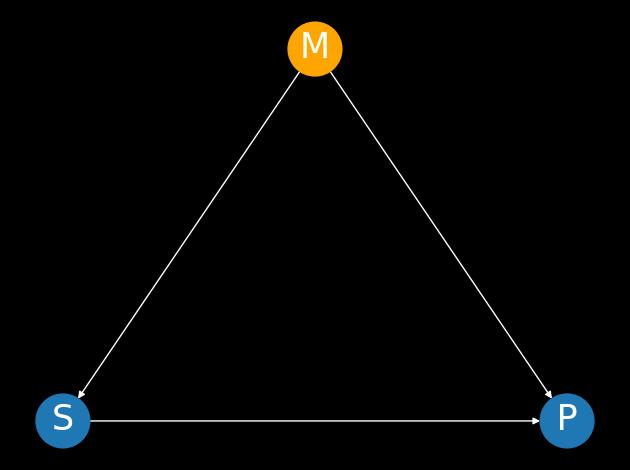

In [13]:
from matplotlib import pyplot as plt
import networkx as nx

graph = nx.DiGraph()

pos = {
    "S": (0,0),
    "M": (1,1),
    "P": (2,0)
}

graph.add_edges_from([("S", "P"), ("M", "S"), ("M","P")])

colors = ["orange" if node == "M" else "#1f78b4" for node in graph.nodes()]

fig = plt.figure(facecolor="black")

nx.draw_networkx(
    graph, 
    arrows=True, 
    node_size=1500, 
    pos=pos, 
    font_size=25, 
    node_color=colors,
    edge_color="white", 
    font_color="white" 
)

plt.axis("off")
plt.tight_layout()
plt.show()

### 2.1. Variables

* **S (Treatment):** Star Radius - The radius of the host star.
* **P (Outcome):** Planet Radius - The radius of the planet.
* **M (Confound):** Star Metallicity - The ratio of iron to hydrogen in the composition of the host star.

### 2.2. Assumed Causal Relationships

We assume that star radius has a positive causal effect on planet radius, even after accounting for star metallicity. Our DAG contains three arrows:

**Star Radius -> Planet Radius:** Larger stars tend to host larger planets. Lozovsky et al. (2021) find that this is best explained by planets around more massive stars accreting thicker atmospheres, which inflates their radius. Because stellar mass and radius increase together, we use stellar radius as our measure of star size.

**Star Metallicity -> Star Radius:** A star's metal ratio affects its temperature and therefore its size. The mechanism behind this is belived to to be due to higher metal compositions increasing a star's internal opacity, trapping energy and causing the star to expand and cool (Mihos, ASTR 222 notes, Case Western). Lower metal ratios would result in the opposite, causing more energy to leave the star, rasing its temperature and keeping its size smaller.

**Star Metallicity -> Planet Radius:** 

Because metallicity influences both star radius and planet radius, it opens a backdoor path. To estimate the causal effect of star radius on planet radius, our model will control for Star Metallicity. We also assume there is no arrow from planet radius back to star radius, since the star forms first and its properties are not affected by its planets.

## 3. Statistical Model

*(Describe the full statistical model you are using, preferably with statistical notation. DO NOT USE THIS EXACT MODEL DEFINITION IF IT IS NOT APPROPRIATE FOR YOUR PROJECT.)*

*(Example:)*  

$$ Y_i \sim \text{Normal}(\mu_i, \sigma) $$
$$ \mu_i = \alpha + \beta_T T_i + \beta_Z Z_i $$
$$ \alpha \sim \text{Normal}(0, 1) $$
$$ \beta_T \sim \text{Normal}(0, 1) $$
$$ \beta_Z \sim \text{Normal}(0, 1) $$
$$ \sigma \sim \text{Exponential}(1) $$

### 3.1. Justification of Priors

*(Justify the priors used in your model. This justification should be the result of prior predictive simulation and using information from outside of the dataset. )*

### 3.2. Justification of Outcome Distribution

*(Explain why your chosen distribution for the outcome variable (e.g., Normal, Bernoulli, Poisson) is reasonable given the observed data. )*

### 3.3. Handling the Confound

*(Explain how your statistical model properly handles the confounding variable to provide a valid causal estimate. )*

In [1]:
# Used packages
import pandas as pd

## 4. Model Validation on Simulated Data

*(Before analyzing the real data, you must validate your statistical model on simulated data where you pre-define the parameter values, construct a posterior approximation of your model using the simulated data, and evaluate how well your model estimates the pre-defined parameter values.)*

*(**Hint:** Use `arviz.plot_posterior()` with the `ref_val` parameter set to your fixed simulation parameter values to check how well your model estimates them. )*

In [ ]:
# 1. Define fixed parameter values (e.g., alpha_sim = 0.3, beta_sim = 0.5, etc)

# 2. Simulate data based on your causal/statistical model using these fixed values

# 3. Run your computational model (using PyMC) on this simulated data

# 4. Check how well your model estimates the parameter values. Do the posterior estimates from the model capture the true values you defined?


*(Provide a brief discussion of the simulation results, confirming that your model can successfully recover the fixed parameters.)*

## 5. Data Preparation (Real Data)

*(Load the real dataset. Perform any necessary cleaning, scaling, or transformations. )*
#### Things to do to prepare our data (formalize later)
    - Drop rows with missing values
    - Remove rows where system has more than 1 star
    - Remove margin of error columns
    - Remove columns based on the type of ratios that they use (Fe/H or M/H)
    - log transform
    - standardize

In [ ]:
# a standardization function using a pandas series object as a argument
def standardize(series):
    return (series - series.mean()) / series.std()

In [ ]:
# COLUMN pl_name:        Planet Name
# COLUMN hostname:       Host Name
# COLUMN default_flag:   Default Parameter Set
# COLUMN sy_snum:        Number of Stars
# COLUMN sy_pnum:        Number of Planets
# COLUMN pl_rade:        Planet Radius [Earth Radius]
# COLUMN pl_radeerr1:    Planet Radius Upper Unc. [Earth Radius]
# COLUMN pl_radeerr2:    Planet Radius Lower Unc. [Earth Radius]
# COLUMN pl_radelim:     Planet Radius Limit Flag
# COLUMN st_rad:         Stellar Radius [Solar Radius]
# COLUMN st_raderr1:     Stellar Radius Upper Unc. [Solar Radius]
# COLUMN st_raderr2:     Stellar Radius Lower Unc. [Solar Radius]
# COLUMN st_radlim:      Stellar Radius Limit Flag
# COLUMN st_met:         Stellar Metallicity [dex]
# COLUMN st_meterr1:     Stellar Metallicity Upper Unc. [dex]
# COLUMN st_meterr2:     Stellar Metallicity Lower Unc. [dex]
# COLUMN st_metlim:      Stellar Metallicity Limit Flag
# COLUMN st_metratio:    Stellar Metallicity Ratio

# Load data 
df = pd.read_csv("Data/exoplanets_data.csv", sep=',', comment='#')

# Count number of rows now in the dataframe
num_rows = df.shape[0]
print("Number of rows in the dataframe before cleaning: ", num_rows)

# Remove duplicates by only using default parameter set of the data
# The default parmeter indicates that it is the preferred parameter set for the planet and host star system
# Might need to adjust since this remove rows that do not have a default parameter set
# The alternative is to just filter out duplicates with priority on default parameter set if it exists
df = df[df['default_flag'] == 1]

# Remove columns for uncertainty in measurements
df = df.drop(columns=['pl_radeerr1', 'pl_radeerr2', 'pl_radelim','st_raderr1', 'st_raderr2', 'st_radlim', 'st_meterr1', 'st_meterr2', 'st_metlim'])

# Remove any rows with missing values
df = df.dropna(subset=['pl_rade', 'st_rad', 'st_met'])

# Remove any rows with number of stars other than 1
df = df[df['sy_snum'] == 1]

# Remove any rows with metallicity ratio [M/H] (using the [Fe/H] ratio since there is more data)
df = df[df['st_metratio'] == '[Fe/H]']

# Count number of rows now in the dataframe
num_rows = df.shape[0]
print("Number of rows in the dataframe after cleaning: ", num_rows)

# Perform any cleaning/scaling/transformations 

Number of rows in the dataframe before cleaning:  40428
Number of rows in the dataframe after cleaning:  3158


## 6. Posterior Model (Analysis on Real Data)

*(This section contains the code for your computational model and the analysis of its output.)*

### 6.1. Computational Model Definition and Sampling

*(Provide the code for your PyMC model.  Ensure the code is well-organized and understandable. )*

In [ ]:
# Define your statistical model in code (e.g., with pm.Model() as model: ...) and sample from the model


### 6.2. Model Diagnostics

*(Use built-in diagnostics to assess the quality of the posterior samples (e.g., trace plots, r-hat, effective sample size). )*

In [ ]:
# Show posterior summary

# Plot trace plots

# Check R-hat and ESS

*(Briefly discuss the diagnostics. Did the model converge? Are the samples of good quality?)*

## 7. Posterior Predictive Checks

*(Visually compare your model's posterior predictions to the observed data. )*

*(The plot(s) in this section should include: )*
* *The observed data*
* *The posterior mean*
* *The uncertainty of the posterior mean (e.g., 89% HDI)*
* *The uncertainty of posterior predictions (e.g., 89% HDI)*

In [ ]:
# Generate posterior predictive samples

# Create the posterior predictive check plot(s)


*(Discuss the results of the check(s). How well does your posterior approximation fit the observed data? Are there any notable discrepancies? )*

## 8. Discussion and Conclusion

### 8.1. Answering the Question

*(Discuss what was learned from the model. )*
* *What is the answer to the question you posed in the introduction?*
* *What is your estimate for the causal effect? Provide a plot showing the estimate of the distribution of the causal effect.*
* *Ensure your conclusions are supported by the evidence from your model results. *

### 8.2. Addressing the Confound

*(Explicitly address the confounding variable in your discussion. )*
* *What was the effect of the confound?*

## 9. Future Work

*(Use your current model results to guide future plans for expanding the analysis. )*

Since our variables are all based on estimates of measurements and contain error values, future work would include the error rate of these measurements into the models. This would be accomplished by treating the real values as unobserved parameters, placing the estimates as the mean value and using the error ranges as the standard deviation. We would then sample the 'true' values from this structure using a Normal distribution.

* *What are the limitations of your model?*
* *What other variables would you want to include to expand your inquiry?*
* *What other questions might you explore given what you have learned from your analysis?*

## 10. Group Member Contributions

*(List each section of the proposal and final write-up and state who worked on it.)*

**Example:**
* **Proposal:** Member Name 1, Member Name 2, Member Name 3
* **Introduction:** Member Name 1
* **Causal Model:** Member Name 2
* **Statistical Model:** Member Name 3
* **Model Validation on Simulated Data:** Member Name 1, Member Name 2
* **Data Preparation:** Member Name 3
* **Posterior Model (Analysis on Real Data):** Member Name 1
* **Posterior Predictive Checks:** Member Name 2
* **Discussion and Conclusion:** Member Name 3
* **Future Work:** Member Name 1, Member Name 2, Member Name 3
